In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
from imports import *

# Harvard sessions: timing and design checks, then compile

Harvard ran each session as one or more short **practice** blocks (100% coherence, no prior) followed by about four
**trial** blocks of 160 trials (80 green, 80 red), for 600+ trials in total. Every block is its own file under
`raw/harvard_data/{pd,hc}/<session>/`:

- `practice/YYMMDD_HHMMSS.mat`
- `trial/YYMMDD_HHMMSS.mat`, or a `.mat` directly inside the session folder (also read as a trial block)

Anything else (a subfolder inside `trial/`, say) is reported and left out.

This notebook works from the raw block files only. For each block it checks

1. **Timing.** Three clocks are compared (below). A block whose timestamps disagree was not recorded in that session.
2. **Design.** The per-colour target split, and the prior it implies. Every trial block in a session should show the same prior.
3. **Order.** Practice finished before the first trial block started, and trial blocks follow one another without overlapping.

and then writes, to `compiled/harvard/`:

| file | contents |
|---|---|
| `blocks.csv` | one row per raw file: timestamps, checks, design, `use` and `excluded_reason` |
| `session_summary.csv` | one row per session: block counts, prior consistency, order checks, `issues` |
| `sessions/<session>.parquet` | the session's trials from the blocks with `use`, practice then trial, in time order |

Nothing is screened for accuracy or design here. Sessions with an inconsistent prior or a partial block are compiled
and flagged, so the decision about them can be made, and changed, downstream.

### Three clocks per block

- **Filename** (`YYMMDD_HHMMSS`): when the task program started the block. The first trial can follow some minutes later.
- **MAT header** (`Created on: ...`, written by MATLAB's `save`): when the block was saved, about 15 s after its last trial.
- **`time` matrix**: event times in milliseconds on the PC's monotonic clock. It runs on through a whole session, so
  the offset *header time − last clock value* is the same for every block recorded on that machine that day.

Hence, for a genuine block:

- header − filename ≥ recorded duration (last − first clock value), give or take a few seconds;
- its header offset matches the session's (the median over the session's trial blocks) to within a minute.

Filesystem modification times are not used: they record when files were copied, not when they were recorded.

In [2]:
import hashlib
import re

import scipy.io

from config import main_config
from src.data_io import catalog
from src.utils.sessions import SESSION_COLUMNS, decode_events, prior_design_error

CLOCK_TOLERANCE_S = 60  # a block's header offset may differ from its session's by this much
RECORDING_SLACK_S = 5  # header - filename may fall short of the recorded duration by this much (1 s filename resolution)
MIN_TRIALS_PER_BLOCK = 10  # fewer rows (or an event matrix without 10 columns) is an aborted start
FULL_BLOCK = 150  # trial blocks with fewer colour-shown trials than this are partial (a full block shows 160)
MIN_SESSION_TRIALS = 600  # the intended session length, in colour-shown trials
BIAS_PCT = 60  # a colour whose targets go more than this % to one side carries a prior
DESIGN_TOLERANCE = main_config.BEHAVIOR.prior_design_tolerance
EPOCH = pd.Timestamp("2000-01-01")  # any fixed origin; only differences of header offsets matter

GROUPS = {"pd": catalog.path("raw_harvard_sessions", subject_type="pd"), "hc": catalog.path("raw_harvard_sessions", subject_type="hc")}
HARVARD = GROUPS["pd"].parent


def natural_key(folder):
    """P25_off before P25_on before P26_off; HC2 before HC10."""
    number = re.search(r"\d+", folder.name)
    return (int(number.group()) if number else 0, folder.name)


def block_phase(file, folder):
    parts = file.relative_to(folder).parts
    if len(parts) == 1:
        return "trial"  # directly inside the session folder
    if len(parts) == 2 and parts[0] in ("practice", "trial"):
        return parts[0]
    return "unexpected"


def header_time(mat):
    """The `Created on:` time in a MAT-file header (MATLAB pads single-digit days with a space)."""
    found = re.search(r"Created on: (.+?\d{4})", mat["__header__"].decode("latin1"))
    return pd.to_datetime(" ".join(found.group(1).split()), format="%a %b %d %H:%M:%S %Y") if found else pd.NaT

## 1. Inventory: every `.mat` file under each session folder

In [3]:
rows, raw = [], {}  # raw: file -> (event, time)
for group, group_dir in GROUPS.items():
    for folder in sorted((f for f in group_dir.iterdir() if f.is_dir()), key=natural_key):
        subject_id, _, medication = folder.name.partition("_")
        for file in sorted(folder.rglob("*.mat")):
            mat = scipy.io.loadmat(file)
            event, time = mat["event"], mat["time"]
            key = file.relative_to(HARVARD).as_posix()
            raw[key] = (event, time)
            rows.append(
                {
                    "session_id": folder.name,
                    "subject_id": subject_id.upper(),
                    "group": group,
                    "medication": medication.lower() or None,
                    "phase": block_phase(file, folder),
                    "file": key,
                    "filename_time": pd.to_datetime(file.stem, format="%y%m%d_%H%M%S", errors="coerce"),
                    "header_time": header_time(mat),
                    "n_rows": event.shape[0],
                    "n_cols": event.shape[1],
                    "clock_start_s": time[0, 0] / 1000,
                    "clock_end_s": time[time > 0].max() / 1000,
                    "content_md5": hashlib.md5(event.tobytes() + time.tobytes()).hexdigest(),
                }
            )
blocks = pd.DataFrame(rows)
print(f"{len(blocks)} files in {blocks.session_id.nunique()} sessions "
      f"({blocks[blocks.group == 'pd'].subject_id.nunique()} patients, {blocks[blocks.group == 'hc'].subject_id.nunique()} controls)")
blocks.pivot_table(index="session_id", columns="phase", values="file", aggfunc="size", sort=False).fillna(0).astype(int).T

209 files in 35 sessions (10 patients, 15 controls)


session_id,P25_off,P25_on,P26_off,P26_on,P27_off,P27_on,P28_off,P28_on,P29_off,P29_on,P30_off,P30_on,P31_off,P31_on,P32_off,P32_on,P33_off,P33_on,P34_off,P34_on,HC1,HC2,HC3,HC5,HC6,HC7,HC8,HC9,HC10,HC11,HC12,HC13,HC14,HC15,HC16
phase,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
practice,3,2,3,4,2,4,1,2,1,2,1,2,1,2,1,1,1,2,1,1,3,2,1,3,1,2,2,1,1,2,1,2,1,1,5
trial,4,4,4,4,4,4,5,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,5,4,4,4,4,4,4,4,4,4
unexpected,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2


## 2. Timing checks

In [4]:
blocks["duration_s"] = blocks.clock_end_s - blocks.clock_start_s
blocks["header_minus_filename_s"] = (blocks.header_time - blocks.filename_time).dt.total_seconds()
blocks["wait_s"] = blocks.header_minus_filename_s - blocks.duration_s  # program start -> first trial, plus the save after the last
blocks["header_offset_s"] = (blocks.header_time - EPOCH).dt.total_seconds() - blocks.clock_end_s

complete = (blocks.n_cols == 10) & (blocks.n_rows >= MIN_TRIALS_PER_BLOCK)
session_offset = blocks[complete & (blocks.phase == "trial")].groupby("session_id").header_offset_s.median()
blocks["clock_drift_s"] = blocks.header_offset_s - blocks.session_id.map(session_offset)

blocks["header_same_day"] = blocks.header_time.dt.date == blocks.filename_time.dt.date
blocks["saved_after_recording"] = blocks.wait_s >= -RECORDING_SLACK_S
blocks["on_session_clock"] = blocks.clock_drift_s.abs() <= CLOCK_TOLERANCE_S

same_content = blocks.groupby("content_md5").file.transform(lambda f: [", ".join(sorted(set(f) - {x})) for x in f])
blocks["duplicate_of"] = same_content.replace("", None)

timing_cols = ["file", "filename_time", "header_time", "n_rows", "duration_s", "wait_s", "clock_drift_s", "duplicate_of"]
timing_ok = blocks.header_same_day & blocks.saved_after_recording & blocks.on_session_clock
print(f"{timing_ok.sum()} of {len(blocks)} files pass all timing checks. The others:")
blocks.loc[~timing_ok, timing_cols].round(0)

194 of 209 files pass all timing checks. The others:


,file,filename_time,header_time,n_rows,duration_s,wait_s,clock_drift_s,duplicate_of
1,pd/P25_off/practice/250318_095304.mat,2025-03-18 09:53:04,2025-02-28 09:31:21,51,126.0,-1556629.0,-1525645.0,hc/HC7/practice/250228_092900.mat
2,pd/P25_off/practice/250318_095525.mat,2025-03-18 09:55:25,2025-04-28 08:48:23,50,104.0,3538274.0,3296499.0,"hc/HC11/practice/250428_084625.mat, pd/P26_off..."
7,pd/P25_on/practice/250325_100753.mat,2025-03-25 10:07:53,2025-04-28 11:30:25,52,132.0,2942420.0,2778254.0,None
8,pd/P25_on/practice/250325_100951.mat,2025-03-25 10:09:51,2025-04-28 11:33:10,54,123.0,2942476.0,2778254.0,None
14,pd/P26_off/practice/250401_065823.mat,2025-04-01 06:58:23,2025-04-28 08:48:23,50,104.0,2339296.0,2199557.0,"hc/HC11/practice/250428_084625.mat, pd/P25_off..."
15,pd/P26_off/practice/250401_070015.mat,2025-04-01 07:00:15,2025-04-28 10:24:01,51,115.0,2344911.0,2199556.0,None
20,pd/P26_on/practice/250415_063733.mat,2025-04-15 06:37:33,2025-04-28 10:59:44,55,107.0,1138824.0,1108193.0,None
21,pd/P26_on/practice/250415_063849.mat,2025-04-15 06:38:49,2025-04-28 11:04:04,50,108.0,1139007.0,1108193.0,None
22,pd/P26_on/practice/250415_063902.mat,2025-04-15 06:39:02,2025-04-28 11:04:49,2,3.0,1139144.0,1108194.0,None
23,pd/P26_on/practice/250428_064118.mat,2025-04-28 06:41:18,2025-04-28 11:07:53,50,107.0,15888.0,1108193.0,None


Among the files that pass, the wait between program start and save beyond the recorded trials, and the clock drift:

In [5]:
blocks.loc[timing_ok, ["wait_s", "clock_drift_s"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
wait_s,194.0,48.2,86.9,-1.9,15.8,18.6,35.2,861.4
clock_drift_s,194.0,0.2,1.9,-10.3,-0.2,0.0,0.2,11.0


## 3. Which files are used

A file is left out, for the first reason that applies, when it

1. sits outside `practice/` and `trial/` (and is not directly in the session folder);
2. is an aborted start (not a 10-column event matrix, or under 10 rows);
3. was not recorded in this session: its header offset is off the session's clock, or it was saved before its own
   trials could have ended (a renamed copy);
4. repeats the contents of an earlier used file of the same session.

In [6]:
def excluded_reason(block):
    if block.phase == "unexpected":
        return "outside practice/ and trial/"
    if block.n_cols != 10 or block.n_rows < MIN_TRIALS_PER_BLOCK:
        return f"aborted ({block.n_rows} x {block.n_cols} event matrix)"
    if not block.on_session_clock:
        return f"not on this session's clock (saved {block.header_time:%Y-%m-%d %H:%M})"
    if not block.saved_after_recording:
        return f"saved {-block.wait_s:.0f} s before its trials ended"
    return None


blocks["excluded_reason"] = blocks.apply(excluded_reason, axis=1)
kept = blocks.excluded_reason.isna()
repeat = kept & blocks[kept].sort_values("filename_time").duplicated(["session_id", "content_md5"]).reindex(blocks.index, fill_value=False)
blocks.loc[repeat, "excluded_reason"] = "repeats an earlier block of this session"
blocks["use"] = blocks.excluded_reason.isna()

print(f"using {blocks.use.sum()} of {len(blocks)} files; left out:")
blocks.loc[~blocks.use, ["file", "header_time", "n_rows", "excluded_reason", "duplicate_of"]]

using 190 of 209 files; left out:


,file,header_time,n_rows,excluded_reason,duplicate_of
1,pd/P25_off/practice/250318_095304.mat,2025-02-28 09:31:21,51,not on this session's clock (saved 2025-02-28 ...,hc/HC7/practice/250228_092900.mat
2,pd/P25_off/practice/250318_095525.mat,2025-04-28 08:48:23,50,not on this session's clock (saved 2025-04-28 ...,"hc/HC11/practice/250428_084625.mat, pd/P26_off..."
7,pd/P25_on/practice/250325_100753.mat,2025-04-28 11:30:25,52,not on this session's clock (saved 2025-04-28 ...,None
8,pd/P25_on/practice/250325_100951.mat,2025-04-28 11:33:10,54,not on this session's clock (saved 2025-04-28 ...,None
14,pd/P26_off/practice/250401_065823.mat,2025-04-28 08:48:23,50,not on this session's clock (saved 2025-04-28 ...,"hc/HC11/practice/250428_084625.mat, pd/P25_off..."
15,pd/P26_off/practice/250401_070015.mat,2025-04-28 10:24:01,51,not on this session's clock (saved 2025-04-28 ...,None
20,pd/P26_on/practice/250415_063733.mat,2025-04-28 10:59:44,55,not on this session's clock (saved 2025-04-28 ...,None
21,pd/P26_on/practice/250415_063849.mat,2025-04-28 11:04:04,50,not on this session's clock (saved 2025-04-28 ...,None
22,pd/P26_on/practice/250415_063902.mat,2025-04-28 11:04:49,2,aborted (2 x 8 event matrix),None
23,pd/P26_on/practice/250428_064118.mat,2025-04-28 11:07:53,50,not on this session's clock (saved 2025-04-28 ...,None


## 4. Design of each block

For every 10-column block: the share of each colour's targets on the right, the prior that implies (a colour with
more than 60% to one side carries it: `gr` green-right, `rl` red-left, ...; `none` if neither does), and the design
error used by the load-time screen (`src.utils.sessions.prior_design_error`: the larger departure from 75:25 for the
prior colour and 50:50 for the other). Practice blocks should show only 100% coherence and no prior.

In [7]:
decoded = {f: decode_events(*raw[f]) for f in blocks.loc[blocks.n_cols == 10, "file"]}


def block_design(file):
    shown = decoded[file].dropna(subset=["color", "target"])
    design = {"n_shown": len(shown), "coherences": ",".join(str(int(c)) for c in sorted(decoded[file].coherence.dropna().unique()))}
    for colour in ("green", "red"):
        targets = shown.loc[shown.color == colour, "target"]
        design[f"n_{colour}"] = len(targets)
        design[f"{colour}_right_pct"] = 100 * (targets == "right").mean() if len(targets) else np.nan
    return design


def implied_prior(block):
    parts = [f"{colour[0]}{'r' if block[f'{colour}_right_pct'] > 50 else 'l'}"
             for colour in ("green", "red") if abs(block[f"{colour}_right_pct"] - 50) > BIAS_PCT - 50]
    return "+".join(parts) or "none"


design = pd.DataFrame({f: block_design(f) for f in decoded}).T
blocks = blocks.drop(columns=design.columns, errors="ignore").join(design, on="file")
has_design = blocks.n_shown.notna()
blocks.loc[has_design, "block_prior"] = blocks[has_design].apply(implied_prior, axis=1)
errors = prior_design_error(pd.concat([d.assign(session_filename=f) for f, d in decoded.items()]))["prior_design_error"]
blocks["design_error"] = blocks.file.map(errors)
blocks["partial"] = (blocks.phase == "trial") & (blocks.n_shown < FULL_BLOCK)

practice = blocks[blocks.use & (blocks.phase == "practice")]
odd_practice = practice[(practice.coherences != "100") | (practice.block_prior != "none")]
print(f"{len(practice)} used practice blocks; {len(odd_practice)} with coherences other than 100% or a prior")
display(odd_practice[["file", "n_shown", "coherences", "green_right_pct", "red_right_pct", "block_prior"]])

trial_blocks = blocks[blocks.use & (blocks.phase == "trial")]
print(f"{len(trial_blocks)} used trial blocks, {trial_blocks.partial.sum()} partial:")
trial_blocks.loc[trial_blocks.partial, ["file", "n_rows", "n_shown", "green_right_pct", "red_right_pct", "block_prior"]].round(1)

49 used practice blocks; 0 with coherences other than 100% or a prior


,file,n_shown,coherences,green_right_pct,red_right_pct,block_prior


141 used trial blocks, 1 partial:


,file,n_rows,n_shown,green_right_pct,red_right_pct,block_prior
45,pd/P28_off/trial/250520_080718.mat,55,55,78.571429,25.925926,gr+rl


## 5. Session checks

Over each session's used blocks:

- **prior consistent**: every trial block implies the same prior; `session_prior` is the one most blocks show;
- **design ok**: every complete trial block is within the design tolerance of 75:25 / 50:50 (a session run with both
  colours biased is consistent but not ok);
- **practice before trial**: the last practice block was saved before the first trial block started, by the
  filename/header times and by the session clock;
- **trial order**: trial blocks are in the same order by filename, header and clock, and none starts before the
  previous one was saved;
- **one day** and **600+ trials**.

In [8]:
def session_checks(session):
    used = session[session.use]
    practice = used[used.phase == "practice"].sort_values("filename_time")
    trial = used[used.phase == "trial"].sort_values("filename_time")
    full = trial[~trial.partial]
    priors = full.block_prior.value_counts()
    session_prior = priors.index[0] if len(priors) else None
    by_clock = trial.sort_values("clock_start_s").file.tolist()
    by_header = trial.sort_values("header_time").file.tolist()
    gaps = (trial.filename_time.iloc[1:].to_numpy() - trial.header_time.iloc[:-1].to_numpy()) / pd.Timedelta(seconds=1)
    checks = {
        "date": ", ".join(sorted({f"{d:%Y-%m-%d}" for d in used.filename_time})),
        "n_practice_blocks": len(practice),
        "n_trial_blocks": len(trial),
        "n_partial_blocks": int(trial.partial.sum()),
        "n_files_left_out": int((~session.use).sum()),
        "n_trials": int(trial.n_rows.sum()),
        "n_shown": int(trial.n_shown.sum()),
        "block_priors": " | ".join(trial.block_prior + np.where(trial.partial, "*", "")),
        "session_prior": session_prior,
        "prior_consistent": trial.block_prior.nunique() == 1,
        "design_ok": bool((full.design_error <= DESIGN_TOLERANCE).all()),
        "max_design_error": full.design_error.max(),
        "practice_before_trial": bool(len(practice) and practice.header_time.max() <= trial.filename_time.min()
                                      and practice.clock_end_s.max() <= trial.clock_start_s.min()),
        "practice_to_trial_min": (trial.filename_time.min() - practice.header_time.max()).total_seconds() / 60 if len(practice) else np.nan,
        "trial_order_consistent": by_clock == trial.file.tolist() == by_header,
        "trial_blocks_overlap": bool((gaps < -RECORDING_SLACK_S).any()),
        "one_day": used.filename_time.dt.date.nunique() == 1,
        "reaches_600": int(trial.n_shown.sum()) >= MIN_SESSION_TRIALS,
    }
    issues = []
    if not checks["prior_consistent"]:
        issues.append(f"block priors differ ({checks['block_priors']})")
    if not checks["design_ok"]:
        issues.append(f"design off 75:25 / 50:50 (error {checks['max_design_error']:.2f})")
    if not checks["practice_before_trial"]:
        issues.append("no practice recorded in this session" if not len(practice) else "practice not before trial")
    if not checks["trial_order_consistent"] or checks["trial_blocks_overlap"]:
        issues.append("trial block order or overlap")
    if not checks["one_day"]:
        issues.append("blocks on several days")
    if not checks["reaches_600"]:
        issues.append(f"{checks['n_shown']} trials")
    if checks["n_partial_blocks"]:
        issues.append(f"{checks['n_partial_blocks']} partial block(s)")
    if checks["n_files_left_out"]:
        issues.append(f"{checks['n_files_left_out']} file(s) left out")
    checks["issues"] = "; ".join(issues)
    return pd.Series(checks)


first = blocks.drop_duplicates("session_id").set_index("session_id")[["subject_id", "group", "medication"]]
summary = first.join(blocks.groupby("session_id", sort=False).apply(session_checks)).reset_index()
show = ["session_id", "date", "n_practice_blocks", "n_trial_blocks", "n_shown", "block_priors", "session_prior",
        "prior_consistent", "design_ok", "practice_before_trial", "practice_to_trial_min", "trial_order_consistent", "issues"]
summary[show].round(1)

,session_id,date,n_practice_blocks,n_trial_blocks,n_shown,block_priors,session_prior,prior_consistent,design_ok,practice_before_trial,practice_to_trial_min,trial_order_consistent,issues
0,P25_off,2025-03-18,1,4,640,rl | rl | rl | rl,rl,True,True,True,1.4,True,2 file(s) left out
1,P25_on,2025-03-25,0,4,640,rr | rr | rr | rr,rr,True,True,False,NaN,True,no practice recorded in this session; 2 file(s...
2,P26_off,2025-04-01,1,4,640,gl | gl | gl | gl,gl,True,True,True,1.2,True,2 file(s) left out
3,P26_on,2025-04-15,0,4,640,gr | gr | gr | gr,gr,True,True,False,NaN,True,no practice recorded in this session; 4 file(s...
4,P27_off,2025-03-25,0,4,640,rl | rl | rl | rl,rl,True,True,False,NaN,True,no practice recorded in this session; 2 file(s...
5,P27_on,2025-03-14,1,4,640,gl | gl | gl | gl,gl,True,True,True,1.3,True,3 file(s) left out
6,P28_off,2025-05-20,1,5,695,gr+rl | gr+rl | gr+rl* | gr+rl | gr+rl,gr+rl,True,False,True,1.6,True,design off 75:25 / 50:50 (error 0.25); 1 parti...
7,P28_on,2025-06-06,2,4,640,gl | gl | gl | gl,gl,True,True,True,1.4,True,
8,P29_off,2025-05-21,1,4,642,gr+rl | gr+rl | gr+rl | gr+rl,gr+rl,True,False,True,1.6,True,design off 75:25 / 50:50 (error 0.25)
9,P29_on,2025-05-07,2,4,640,gl | gl | gl | gl,gl,True,True,True,1.8,True,


Sessions with something to look at (`*` marks a partial block):

In [9]:
summary.loc[summary.issues != "", ["session_id", "block_priors", "issues"]].style.hide(axis="index")

session_id,block_priors,issues
P25_off,rl | rl | rl | rl,2 file(s) left out
P25_on,rr | rr | rr | rr,no practice recorded in this session; 2 file(s) left out
P26_off,gl | gl | gl | gl,2 file(s) left out
P26_on,gr | gr | gr | gr,no practice recorded in this session; 4 file(s) left out
P27_off,rl | rl | rl | rl,no practice recorded in this session; 2 file(s) left out
P27_on,gl | gl | gl | gl,3 file(s) left out
P28_off,gr+rl | gr+rl | gr+rl* | gr+rl | gr+rl,design off 75:25 / 50:50 (error 0.25); 1 partial block(s)
P29_off,gr+rl | gr+rl | gr+rl | gr+rl,design off 75:25 / 50:50 (error 0.25)
P30_on,gr+rl | gr+rl | gr+rl | gr+rl,design off 75:25 / 50:50 (error 0.25)
P32_on,gr+rl | gr+rl | gr+rl | gr+rl,design off 75:25 / 50:50 (error 0.25)


## 6. Timeline

Each used block on its session's clock, in minutes from the start of the first trial block. Practice should sit left
of zero. Trial blocks carry their implied prior; hatched blocks are partial. Files left out are not drawn.

saved session_timeline.pdf, session_timeline.png


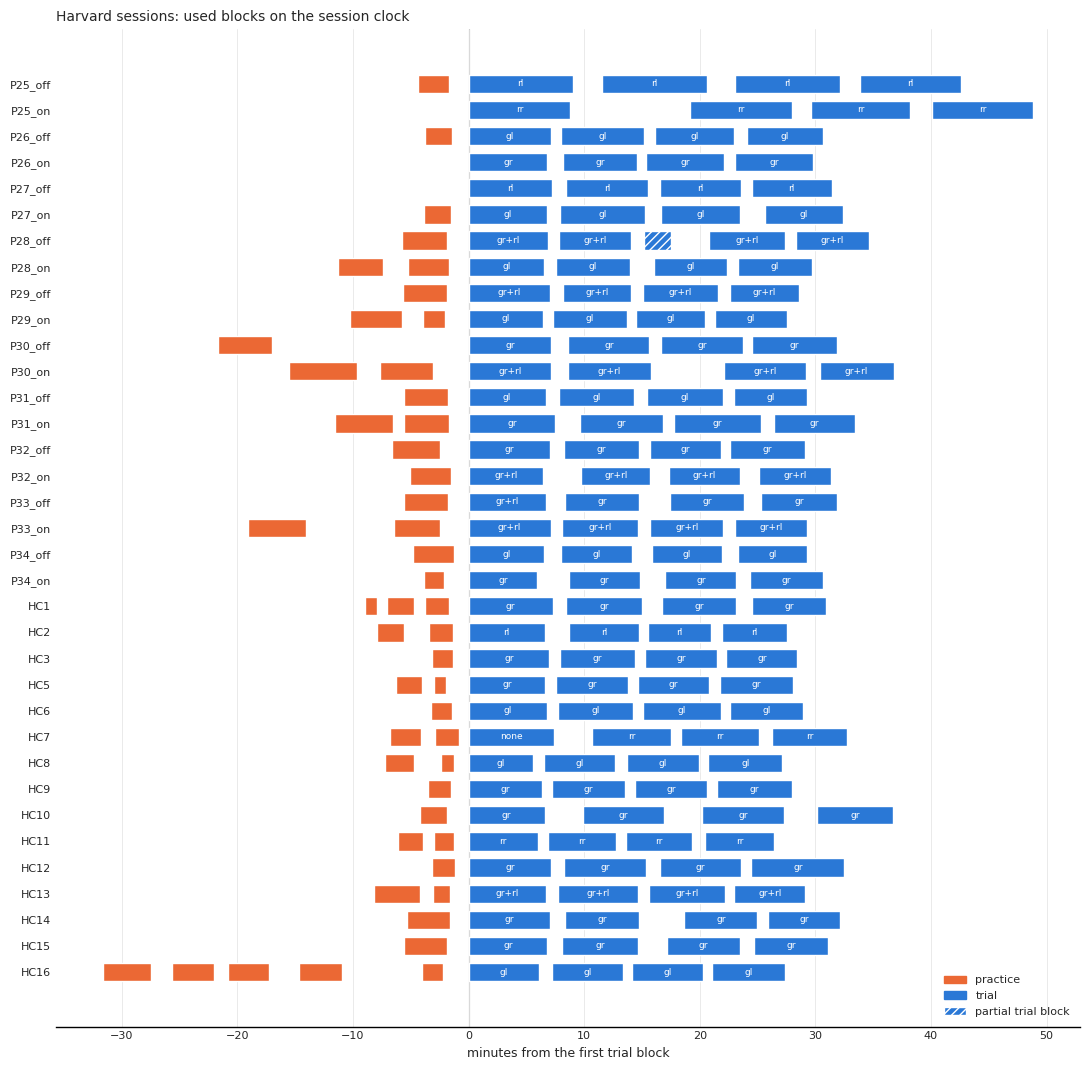

In [10]:
PRACTICE, TRIAL = "#eb6834", "#2a78d6"  # categorical slots 2 and 1 of the reference palette
used = blocks[blocks.use].copy()
t0 = used[used.phase == "trial"].groupby("session_id").clock_start_s.min()
used["start_min"] = (used.clock_start_s - used.session_id.map(t0)) / 60
used["length_min"] = used.duration_s / 60
order = summary.session_id.tolist()

fig, ax = plt.subplots(figsize=(11, 0.28 * len(order) + 1))
for y, session_id in enumerate(order):
    for _, block in used[used.session_id == session_id].iterrows():
        colour = PRACTICE if block.phase == "practice" else TRIAL
        ax.broken_barh([(block.start_min, block.length_min)], (y - 0.35, 0.7), facecolor=colour, edgecolor="white",
                       linewidth=1, hatch="////" if block.partial else None)
        if block.phase == "trial" and block.length_min > 3:
            ax.text(block.start_min + block.length_min / 2, y, block.block_prior, ha="center", va="center", fontsize=6.5, color="white")
ax.axvline(0, color="0.6", linewidth=0.8, zorder=0)
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("minutes from the first trial block", fontsize=9)
ax.tick_params(axis="x", labelsize=8)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="0.9", linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PRACTICE), plt.Rectangle((0, 0), 1, 1, color=TRIAL),
                   plt.Rectangle((0, 0), 1, 1, facecolor=TRIAL, hatch="////", edgecolor="white")],
          labels=["practice", "trial", "partial trial block"], loc="lower right", frameon=False, fontsize=8)
ax.set_title("Harvard sessions: used blocks on the session clock", loc="left", fontsize=10)
plt.tight_layout()
catalog.save_figure(fig, "harvard/session_timeline")
plt.show()

## 7. Compile

Each session's used blocks, practice then trial, each in time order, as one trial table with the shared session
columns plus the block it came from. `prior` is the session's prior (`session_prior`); `prior_color` and
`prior_direction` are filled only when it is a single colour.

In [11]:
BLOCK_COLUMNS = ["session_id", "phase", "block", "block_file", "trial_in_block", "block_prior"]
COLOURS, SIDES = {"g": "green", "r": "red"}, {"r": "right", "l": "left"}

for session in summary.itertuples():
    parts = []
    for phase in ("practice", "trial"):
        phase_blocks = blocks[(blocks.session_id == session.session_id) & blocks.use & (blocks.phase == phase)].sort_values("filename_time")
        for number, block in enumerate(phase_blocks.itertuples(), start=1):
            trials = decoded[block.file].copy()
            trials["phase"], trials["block"], trials["block_file"] = phase, number, block.file
            trials["trial_in_block"] = np.arange(1, len(trials) + 1)
            trials["block_prior"] = block.block_prior
            parts.append(trials)
    trials = pd.concat(parts, ignore_index=True)
    single = session.session_prior in ("gr", "gl", "rr", "rl")
    trials["prior"] = session.session_prior
    trials["prior_color"] = COLOURS[session.session_prior[0]] if single else None
    trials["prior_direction"] = SIDES[session.session_prior[1]] if single else None
    trials["session_id"], trials["subject_id"] = session.session_id, session.subject_id
    trials["group"], trials["medication"] = session.group, session.medication
    trials["session_filename"] = f"{session.session_id}.parquet"
    catalog.save(trials[SESSION_COLUMNS + BLOCK_COLUMNS], "compiled_harvard_session", filename=f"{session.session_id}.parquet")

catalog.save(blocks.drop(columns=["content_md5"]), "compiled_harvard_blocks")
catalog.save(summary, "compiled_harvard_session_summary")

saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P25_off.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P25_on.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P26_off.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P26_on.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P27_off.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P27_on.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P28_off.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P28_on.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P29_off.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P29_on.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P30_off.parquet


...

saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC8.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC9.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC10.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC11.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC12.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC13.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC14.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC15.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC16.parquet
saved compiled_harvard_blocks -> /mnt/pd-data/compiled/harvard/blocks.csv
saved compiled_harvard_session_summary -> /mnt/pd-data/compiled/harvard/session_summary.csv
